# Exploratory Data Analysis

This notebook explores sales in our two fictional mini-market branches. We will look at receipt values, patterns over time, and differences by branch, county, product, and customer type.

## 1. Load the prepared sales data

Run the data_preparation notebook first. This notebook uses its cleaned CSV and leaves that file unchanged. 

In [24]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data" / "processed" / "clean_sales_2025.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

SALES_FILE = ROOT / "data" / "processed" / "clean_sales_2025.csv"
if not SALES_FILE.exists():
    raise FileNotFoundError("Run the data_preparation notebook first to create the cleaned sales file.")

sales = pd.read_csv(SALES_FILE, parse_dates=["sale_date"])
REPORTS_DIR = ROOT / "reports"
print(f"Prepared product lines: {len(sales):,}")
print(f"Sales dates: {sales['sale_date'].min():%d %b %Y} to {sales['sale_date'].max():%d %b %Y}")
sales.head()

Prepared product lines: 1,511
Sales dates: 01 Jan 2025 to 31 Dec 2025


,sale_date,sale_month,transaction_id,store_id,store_name,county,population_2019,location,customer_id,customer_type,product_id,product_name,category,quantity,unit_price_kes,promotion_pct,gross_sales_kes,discount_kes,net_sales_kes,payment_method
0,2025-01-01,2025-01,T00001,S001,Sample CBD Mini-Mart,Nairobi City,4397073,Nairobi CBD,WALK_IN,Walk-in / not identified,P002,Milk 1L,Dairy,2,75,0,150,0.0,150.0,Cash
1,2025-01-01,2025-01,T00001,S001,Sample CBD Mini-Mart,Nairobi City,4397073,Nairobi CBD,WALK_IN,Walk-in / not identified,P009,Water 1.5L,Beverages,2,60,5,120,6.0,114.0,Cash
2,2025-01-01,2025-01,T00002,S001,Sample CBD Mini-Mart,Nairobi City,4397073,Nairobi CBD,C094,loyalty_member,P002,Milk 1L,Dairy,2,75,0,150,0.0,150.0,M-Pesa
3,2025-01-01,2025-01,T00002,S001,Sample CBD Mini-Mart,Nairobi City,4397073,Nairobi CBD,C094,loyalty_member,P008,Tea leaves 250g,Beverages,1,150,0,150,0.0,150.0,M-Pesa
4,2025-01-01,2025-01,T00003,S002,Sample Ruiru Mini-Mart,Kiambu,2417735,Ruiru,C018,regular,P001,Maize flour 2kg,Staples,3,180,0,540,0.0,540.0,M-Pesa


## 2. What does a typical receipt look like?

A transaction can contain several products, so first we add the product lines on each receipt. The histogram shows how receipt totals are spread out. The median is the middle receipt value; the mean is the average. A few large receipts can pull the mean upward.

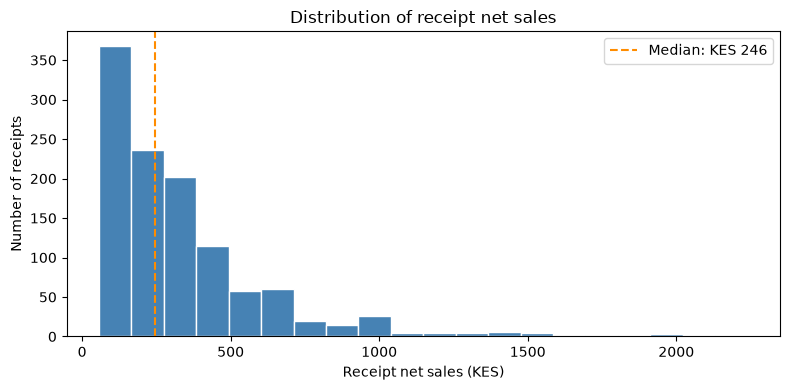

In [25]:
receipt_sales = (
    sales.groupby(["transaction_id", "store_id", "store_name", "county", "customer_type", "sale_date"], as_index=False)
    .agg(
        receipt_net_sales_kes=("net_sales_kes", "sum"),
        receipt_units=("quantity", "sum"),
    )
)
receipt_values = receipt_sales["receipt_net_sales_kes"]
receipt_summary = pd.DataFrame({
    "measure": ["Number of receipts", "Smallest receipt (KES)", "Median receipt (KES)", "Average receipt (KES)", "Largest receipt (KES)"],
    "value": [len(receipt_values), receipt_values.min(), receipt_values.median(), receipt_values.mean(), receipt_values.max()],
})
receipt_summary["value"] = receipt_summary["value"].round(2)
receipt_summary

plt.figure(figsize=(8, 4))
plt.hist(receipt_values, bins=20, color="steelblue", edgecolor="white")
plt.axvline(receipt_values.median(), color="darkorange", linestyle="--", label=f"Median: KES {receipt_values.median():,.0f}")
plt.title("Distribution of receipt net sales")
plt.xlabel("Receipt net sales (KES)")
plt.ylabel("Number of receipts")
plt.legend()
plt.tight_layout()
plt.show()

## 3. How did sales change over time?

This line chart shows monthly net sales for each branch. It helps us spot months that were higher or lower in this sample. Because we only have one year, we can describe a monthly pattern but cannot prove that it repeats every year.

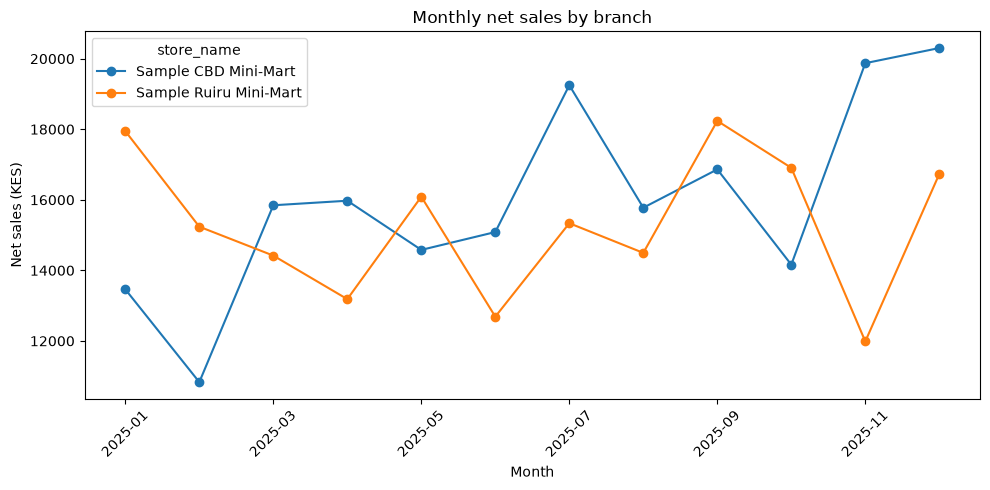

In [26]:
monthly_sales = (
    sales.groupby(["sale_month", "store_name"], as_index=False)
    .agg(net_sales_kes=("net_sales_kes", "sum"), units_sold=("quantity", "sum"))
    .sort_values(["sale_month", "store_name"])
)
monthly_sales.head(8)

monthly_chart = monthly_sales.pivot(index="sale_month", columns="store_name", values="net_sales_kes")
ax = monthly_chart.plot(marker="o", figsize=(10, 5))
ax.set_title("Monthly net sales by branch")
ax.set_xlabel("Month")
ax.set_ylabel("Net sales (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4. Is there a weekly pattern?

We total sales for each date, then calculate the average daily sales for each weekday. Averaging by day helps compare weekdays fairly. This is a weekly pattern in our sample, not proof of why the pattern happens.

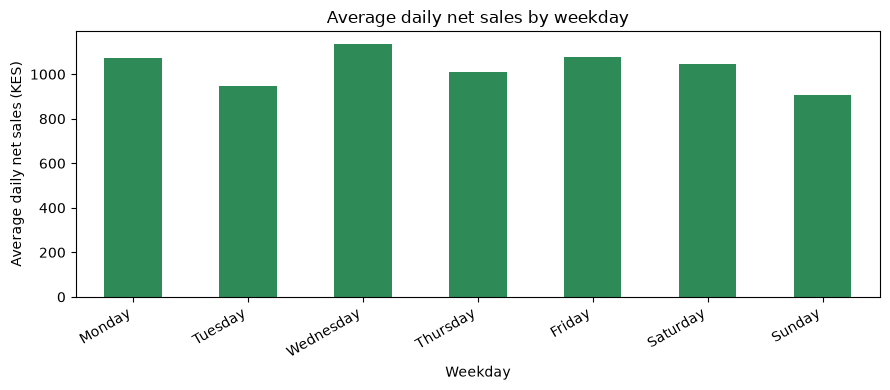

In [27]:
daily_sales = sales.groupby("sale_date", as_index=False).agg(net_sales_kes=("net_sales_kes", "sum"))
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily_sales["weekday"] = pd.Categorical(daily_sales["sale_date"].dt.day_name(), categories=weekday_order, ordered=True)
weekday_summary = (
    daily_sales.groupby("weekday", as_index=False, observed=True)
    .agg(average_daily_net_sales_kes=("net_sales_kes", "mean"), days_observed=("sale_date", "count"))
)
weekday_summary["average_daily_net_sales_kes"] = weekday_summary["average_daily_net_sales_kes"].round(2)
weekday_summary

weekday_chart = weekday_summary.set_index("weekday")["average_daily_net_sales_kes"]
ax = weekday_chart.plot(kind="bar", figsize=(9, 4), color="seagreen")
ax.set_title("Average daily net sales by weekday")
ax.set_xlabel("Weekday")
ax.set_ylabel("Average daily net sales (KES)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 5. How do the branches and counties compare?

We compare receipts, units sold, and net sales. Each county has only one fictional branch in this project, so the county result is the same branch comparison. We cannot separate a county effect from a branch effect with only one branch in each county.

In [28]:
store_summary = (
    sales.groupby(["store_id", "store_name", "county"], as_index=False)
    .agg(
        receipts=("transaction_id", "nunique"),
        units_sold=("quantity", "sum"),
        net_sales_kes=("net_sales_kes", "sum"),
    )
)
store_summary["average_net_sales_per_receipt_kes"] = (store_summary["net_sales_kes"] / store_summary["receipts"]).round(2)
store_summary = store_summary.sort_values("net_sales_kes", ascending=False)
store_summary

county_summary = (
    sales.groupby("county", as_index=False)
    .agg(
        receipts=("transaction_id", "nunique"),
        units_sold=("quantity", "sum"),
        net_sales_kes=("net_sales_kes", "sum"),
    )
)
county_summary

,county,receipts,units_sold,net_sales_kes
0,Kiambu,559,1096,183256.0
1,Nairobi City,575,1146,192003.5


## 6. Which products and categories perform best?

The product table shows both units and net sales. The chart ranks the ten products by net sales. Sales value and number of units are different measures: a high-priced product can earn more while selling fewer units.

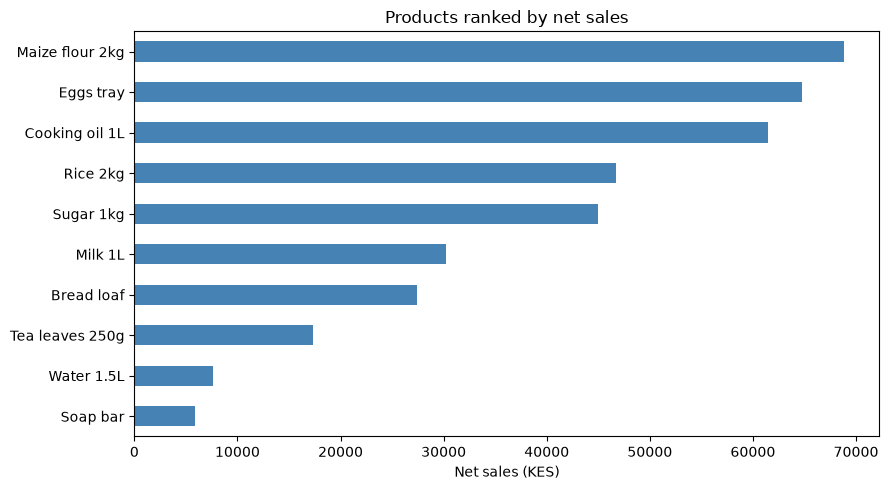

In [29]:
product_summary = (
    sales.groupby(["product_id", "product_name", "category"], as_index=False)
    .agg(units_sold=("quantity", "sum"), net_sales_kes=("net_sales_kes", "sum"))
    .sort_values("net_sales_kes", ascending=False)
)
product_summary

category_summary = (
    sales.groupby("category", as_index=False)
    .agg(units_sold=("quantity", "sum"), net_sales_kes=("net_sales_kes", "sum"))
    .sort_values("net_sales_kes", ascending=False)
)
category_summary

top_products = product_summary.head(10).sort_values("net_sales_kes")
ax = top_products.plot(kind="barh", x="product_name", y="net_sales_kes", legend=False, figsize=(9, 5), color="steelblue")
ax.set_title("Products ranked by net sales")
ax.set_xlabel("Net sales (KES)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 7. How do customer types compare?

We compare sales by customer type using receipts, units, and net sales. The walk-in group represents purchases without an ID; it is not a count of individual walk-in customers.

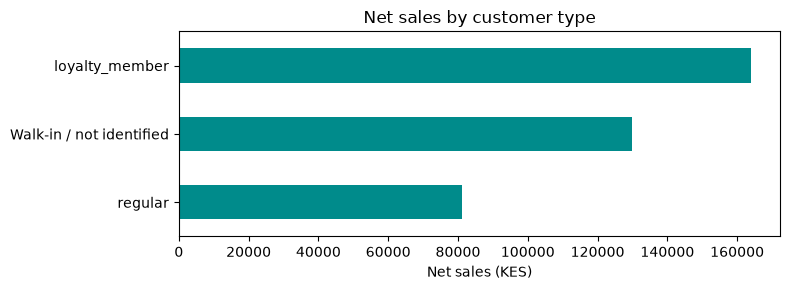

In [30]:
segment_summary = (
    sales.groupby("customer_type", as_index=False)
    .agg(
        receipts=("transaction_id", "nunique"),
        units_sold=("quantity", "sum"),
        net_sales_kes=("net_sales_kes", "sum"),
    )
)
segment_summary["share_of_net_sales_pct"] = (segment_summary["net_sales_kes"] / sales["net_sales_kes"].sum() * 100).round(1)
segment_summary = segment_summary.sort_values("net_sales_kes", ascending=False)
segment_summary

ax = segment_summary.sort_values("net_sales_kes").plot(kind="barh", x="customer_type", y="net_sales_kes", legend=False, figsize=(8, 3), color="darkcyan")
ax.set_title("Net sales by customer type")
ax.set_xlabel("Net sales (KES)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 8. The five findings that matter most

The notebook creates these findings from the tables above.

In [32]:
total_net_sales = round(sales["net_sales_kes"].sum(), 2)
month_totals = sales.groupby("sale_month")["net_sales_kes"].sum()
top_product = product_summary.iloc[0]
top_month = month_totals.idxmax()
low_month = month_totals.idxmin()
top_weekday = weekday_summary.sort_values("average_daily_net_sales_kes", ascending=False).iloc[0]
low_weekday = weekday_summary.sort_values("average_daily_net_sales_kes").iloc[0]
top_store = store_summary.iloc[0]
other_store = store_summary.iloc[1]
branch_difference_pct = (top_store["net_sales_kes"] / other_store["net_sales_kes"] - 1) * 100
top_segment = segment_summary.iloc[0]
median_receipt = receipt_values.median()
average_receipt = receipt_values.mean()

findings = [
    f"Product: {top_product['product_name']} led net sales at KES {top_product['net_sales_kes']:,.2f}, with {int(top_product['units_sold']):,} units sold.",
    f"Time pattern: {top_month} was the strongest month (KES {month_totals.max():,.2f}); {low_month} was the weakest (KES {month_totals.min():,.2f}). Average daily sales were highest on {top_weekday['weekday']} and lowest on {low_weekday['weekday']}.",
    f"Branch and county: {top_store['store_name']} in {top_store['county']} had KES {top_store['net_sales_kes']:,.2f}, {branch_difference_pct:.1f}% above the other branch. Each county has only one sample branch.",
    f"Customer type: {top_segment['customer_type']} had the largest net sales share at {top_segment['share_of_net_sales_pct']:.1f}%. Walk-in sales combine purchases without customer IDs.",
    f"Receipt values: the median receipt was KES {median_receipt:,.2f} and the average was KES {average_receipt:,.2f}; the higher average suggests a small number of larger receipts pull the average upward.",
]

for number, finding in enumerate(findings, start=1):
    print(f"{number}. {finding}")

# Each grouping should add back to the same total net sales.
assert round(product_summary["net_sales_kes"].sum(), 2) == total_net_sales
assert round(monthly_sales["net_sales_kes"].sum(), 2) == total_net_sales
assert round(store_summary["net_sales_kes"].sum(), 2) == total_net_sales
assert round(county_summary["net_sales_kes"].sum(), 2) == total_net_sales
assert round(segment_summary["net_sales_kes"].sum(), 2) == total_net_sales

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
with (REPORTS_DIR / "findings.txt").open("w", encoding="utf-8") as file:
    file.write("\n".join(f"{i}. {finding}" for i, finding in enumerate(findings, start=1)))
print(f"\nTotal net sales checked: KES {total_net_sales:,.2f}")
print("Findings saved to reports/findings.txt")

1. Product: Maize flour 2kg led net sales at KES 68,823.00, with 387 units sold.
2. Time pattern: 2025-12 was the strongest month (KES 37,034.75); 2025-02 was the weakest (KES 26,069.25). Average daily sales were highest on Wednesday and lowest on Sunday.
3. Branch and county: Sample CBD Mini-Mart in Nairobi City had KES 192,003.50, 4.8% above the other branch. Each county has only one sample branch.
4. Customer type: loyalty_member had the largest net sales share at 43.7%. Walk-in sales combine purchases without customer IDs.
5. Receipt values: the median receipt was KES 246.25 and the average was KES 330.92; the higher average suggests a small number of larger receipts pull the average upward.

Total net sales checked: KES 375,259.50
Findings saved to reports/findings.txt
